<div style="text-align: center;">
   <font size="5"> 2025年度　数値計算実習　最終個別試験問題 </font>
</div>
   <div style="text-align: right;">
   <font size="3"> cc by Shigeto R. Nishitani, 2025/12/18実施 </font>
</div>

- file: ~/symbolic_math/exam_25_pair/25_final_ans.ipynb
- make problem: pick_works_from_ans 25_final_ans.ipynb -1 '' '3 17 25'

以下の問題を python で解き，LUNA へ提出せよ．LUNA へは ipynb と pdf 形式の２種類を提出すること．

# 問１微積分

## 2次元表示と極少(15点)

$$
f = (a - x)^2 + b (y - x^2)^2
$$
でa=1, b=2の場合の3次元プロットは次の通りである．

極値とその座標を求めよ．

In [1]:
%matplotlib notebook

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # 3Dプロット用

def f(x, y, a=1, b=2):
    return (a - x)**2 + b * (y - x**2)**2

# x, y の範囲と分割数
x = np.linspace(-2, 2, 400)
y = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# サーフェスを描画
ax.plot_surface(X, Y, Z, rstride=8, cstride=8, linewidth=0.2, antialiased=True)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")

ax.scatter(1, 1, f(1, 1), s=50, marker='o')

plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

In [2]:
import sympy as sp

# 記号の定義
x, y, a, b = sp.symbols('x y a b', real=True)
# 必要なら b>0 と仮定したい場合は：
# x, y, a = sp.symbols('x y a', real=True)
# b = sp.symbols('b', real=True, positive=True)

# 関数 f
f = (a - x)**2 + b * (y - x**2)**2

# 一階偏微分
fx = sp.diff(f, x)
fy = sp.diff(f, y)

print("df/dx =", fx)
print("df/dy =", fy)

# 勾配 = 0 の方程式を解く（臨界点）
crit_points = sp.solve([fx, fy], (x, y), dict=True)
print("critical points:")
for sol in crit_points:
    print(sol)

# ---- 分類したければヘッセ行列も計算 ----
H = sp.hessian(f, (x, y))
print("Hessian:")
sp.pprint(H)

# 各臨界点でヘッセ行列を評価
for sol in crit_points:
    H_at_sol = H.subs(sol)
    print("\nHessian at", sol, ":")
    sp.pprint(H_at_sol)
    print("det =", sp.simplify(H_at_sol.det()))

df/dx = -2*a - 4*b*x*(-x**2 + y) + 2*x
df/dy = b*(-2*x**2 + 2*y)
critical points:
{x: a, y: a**2}
Hessian:
⎡     2       ⎛   2    ⎞            ⎤
⎢8⋅b⋅x  - 4⋅b⋅⎝- x  + y⎠ + 2  -4⋅b⋅x⎥
⎢                                   ⎥
⎣          -4⋅b⋅x              2⋅b  ⎦

Hessian at {x: a, y: a**2} :
⎡   2              ⎤
⎢8⋅a ⋅b + 2  -4⋅a⋅b⎥
⎢                  ⎥
⎣  -4⋅a⋅b     2⋅b  ⎦
det = 4*b


In [3]:
f.subs({x: 1, y: 1, a: 1})

0

## plot(15点)


極値の周りを拡大したplotを作成し．極小値となっていることを示せ．

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

a = 1
b = 2

x = np.linspace(0.5, 1.5, 400)
y = np.linspace(0.5, 1.5, 400)
X, Y = np.meshgrid(x, y)

Z = (a - X)**2 + b * (Y - X**2)**2

# ★ z > 0.01 をマスクする（描かない）
Z_masked = np.where(Z <= 0.1, Z, np.nan)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(
    X, Y, Z_masked,
    edgecolor='none',
    linewidth=0,
    antialiased=False
)

ax.scatter(1, 1, 0, s=80, c='r')

ax.set_title("Rosenbrock bottom (masked z>0.01)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")

# z 軸は自由に拡大可能
ax.set_zlim(0, 0.1)

plt.tight_layout()
plt.show()


<IPython.core.display.Javascript object>

# 問２　線形代数

## 線型結合(15 点)

$\mathbb{R}^5$の部分空間$V$
$$
        V = \left\{
        \left(
        \begin{array}{@{\,}r@{\,}}
          x_1 \\
          x_2 \\
          x_3 \\
          x_4 \\
          x_5
        \end{array}\right)
        \in \mathbb{R}^5
        \left|
        \begin{array}{@{\,}rrrrrr@{\,}}
          x_1 &      & +x_3 & +x_4 &      &=0\\
         -x_1 & +x_2 &      & -x_4 & +x_5 &=0\\
              &  x_2 & +x_3 &      & +x_5 &=0\\
          x_1 & -x_2 &      & +x_4 & -x_5 &=0\\
        \end {array}
        \right.
        \right\}
$$
を考える．$V$の1組の基底および，$V$の直交補空間$V^\perp$の1組の基底を求めよ．

それぞれの基底が直交していることを確認せよ．

In [5]:
import sympy as sp

# 変数は使わないが、念のため定義しておいてもよい
x1, x2, x3, x4, x5 = sp.symbols('x1 x2 x3 x4 x5')

# 与えられた方程式
# x1      + x3 + x4      = 0
# -x1 + x2      - x4 + x5 = 0
#      x2 + x3      + x5 = 0
# x1 - x2      + x4 - x5 = 0
#
# なので A x = 0 の A は：
A = sp.Matrix([
    [ 1,  0, 1,  1,  0],
    [-1,  1, 0, -1,  1],
    [ 0,  1, 1,  0,  1],
    [ 1, -1, 0,  1, -1]
])

# --- V の基底（A x = 0 の解空間 = Ker(A)）---
V_basis = A.nullspace()   # 列ベクトルのリストとして返る

print("Basis for V (Ker A):")
for v in V_basis:
    sp.pprint(v)
    print()

# --- V^⊥ の基底（Row(A) = Ker(A) の直交補空間）---
# R^5 では (Ker A)^\perp = Row(A) なので、
# A の行空間の基底をとればよい
Vperp_basis = A.rowspace()   # 行ベクトルのリスト

print("Basis for V^perp (Row space of A):")
for w in Vperp_basis:
    sp.pprint(w)
    print()
    

Basis for V (Ker A):
⎡-1⎤
⎢  ⎥
⎢-1⎥
⎢  ⎥
⎢1 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎣0 ⎦

⎡-1⎤
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢1 ⎥
⎢  ⎥
⎣0 ⎦

⎡0 ⎤
⎢  ⎥
⎢-1⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎣1 ⎦

Basis for V^perp (Row space of A):
[1  0  1  1  0]

[0  1  1  0  1]



In [6]:
for i in range(len(V_basis)):       # 0..2
    for j in range(len(Vperp_basis)):  # 0..1
        ip = V_basis[i].dot(Vperp_basis[j])
        print(f"inner(V_basis[{i}], Vperp_basis[{j}]) = {ip}")

inner(V_basis[0], Vperp_basis[0]) = 0
inner(V_basis[0], Vperp_basis[1]) = 0
inner(V_basis[1], Vperp_basis[0]) = 0
inner(V_basis[1], Vperp_basis[1]) = 0
inner(V_basis[2], Vperp_basis[0]) = 0
inner(V_basis[2], Vperp_basis[1]) = 0


## 線型結合(15 点)

ベクトル
$$
        v = 
        \left(
        \begin{array}{@{\,}r@{\,}}
          -2 \\
          3 \\
          -1 \\
          2 \\
          3
        \end{array}\right)
$$
はどの空間に属しているか？　また$v$を基底の線型結合で示せ．


In [7]:
import sympy as sp

# 行列 A（前問と同じ）
A = sp.Matrix([
    [ 1,  0, 1,  1,  0],
    [-1,  1, 0, -1,  1],
    [ 0,  1, 1,  0,  1],
    [ 1, -1, 0,  1, -1]
])

# --- 与えられたベクトル v ---
v = sp.Matrix([-2, 3, -1, 2, 3])

# --- 基底計算 ---
V_basis     = A.nullspace()     # V = Ker(A) の基底
Vperp_basis = A.rowspace()      # V^⊥ = Row(A) の基底

# --- 基底行列を作成 ---
B_V     = sp.Matrix.hstack(*V_basis)           # 5×k
B_Vperp = sp.Matrix.vstack(*Vperp_basis).T     # 5×m（転置して列基底に）

# --- v = B_V * a + B_Vperp * b を解く ---
# B = [B_V | B_Vperp]
B = sp.Matrix.hstack(B_V, B_Vperp)

# 係数ベクトルを求める
coeff = B.gauss_jordan_solve(v)[0]

# 係数を分割：a が V の係数、b が Vperp の係数
k = B_V.shape[1]       # 次元 dim(V)
a = coeff[:k, :]
b = coeff[k:, :]

print("V の基底:")
for v0 in V_basis:
    sp.pprint(v0)
    print()

print("V^perp の基底:")
for w0 in Vperp_basis:
    sp.pprint(w0)
    print()

print("\n--- v を V の線型結合で表す係数 a ---")
sp.pprint(a)

print("\n--- v を V^perp の線型結合で表す係数 b ---")
sp.pprint(b)

# 確認：B_V*a + B_Vperp*b が元の v になるか
print("\nCheck: B_V*a + B_Vperp*b =")
sp.pprint(B_V * a + B_Vperp * b)


V の基底:
⎡-1⎤
⎢  ⎥
⎢-1⎥
⎢  ⎥
⎢1 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎣0 ⎦

⎡-1⎤
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢1 ⎥
⎢  ⎥
⎣0 ⎦

⎡0 ⎤
⎢  ⎥
⎢-1⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎣1 ⎦

V^perp の基底:
[1  0  1  1  0]

[0  1  1  0  1]


--- v を V の線型結合で表す係数 a ---
⎡-2⎤
⎢  ⎥
⎢3 ⎥
⎢  ⎥
⎣1 ⎦

--- v を V^perp の線型結合で表す係数 b ---
⎡-1⎤
⎢  ⎥
⎣2 ⎦

Check: B_V*a + B_Vperp*b =
⎡-2⎤
⎢  ⎥
⎢3 ⎥
⎢  ⎥
⎢-1⎥
⎢  ⎥
⎢2 ⎥
⎢  ⎥
⎣3 ⎦


# 問3 共通テスト(20 点)

2022年度：数学II・B/本試験 第２問[2]

括弧は気にせずに係数，式を表示せよ．


$ b > 0 $ とし，
$ g(x)=x^3 - 3bx + 3b^2 $,
$ h(x)=x^3 - x^2 + b^2 $ とおく。
座標平面上の曲線  $y=g(x)$  を $ C_1 $，曲線 $ y=h(x) $ を $ C_2 $ とする。

$ C_1 $ と $ C_2 $ は 2 点で交わる。これらの交点の $ x $ 座標をそれぞれ
$\alpha, \beta \ (\alpha < \beta) $ とすると，
$
\alpha = \fbox{ サ }  ,\quad
\beta = \fbox{ シス }
$
である。

$ a \le x \le \beta $ の範囲で $ C_1 $ と $ C_2 $ で囲まれた図形の面積を $ S $ とする。
また，$ t > \beta $ とし，$ \beta \le x \le t $ の範囲で $ C_1 $ と $ C_2 $ および直線 $ x = t $ で囲まれた図形の面積を $ T $ とする。

このとき

$$
S = \int_a^\beta \boxed{\text{セ}}\ dx
$$

$$
T = \int_\beta^t \boxed{\text{ソ}}\ dx
$$

$$
S - T = \int_a^t \boxed{\text{タ}}\ dx
$$

であるので

$$
S - T = \frac{\fbox{ チツ }}{ \fbox{ テ }}
\left( 2t^3 - \fbox{ ト } bt^2 +
\fbox{ ナニ } b^2 t - \fbox{ ヌ } b^3 \right)
$$

が得られる。

したがって、 $ S=T $ となるのは
$
t = \frac{\fbox{ ネ }}{\fbox{ ノ }}\ b
$
のときである。

In [8]:
from sympy import *

b, t, x = symbols('b t x')

g = x**3-3*b*x + 3*b**2
h = x**3-x**2 + b**2
#b = 0.1
# b に 0.1 を代入した式を用意する
g_sub = g.subs(b, 0.1)
h_sub = h.subs(b, 0.1)

# 代入済みの式と、b=0.1 を反映させた範囲でプロットする
pf = plot(g_sub, h_sub, (x, 0.1 - 0.1, 0.1 / 2 * 5))


<IPython.core.display.Javascript object>

In [9]:
solve(g-h,x)


[b, 2*b]

In [10]:
integrate(h-g,(x,b,2*b))

b**3/6

In [11]:
integrate(g-h,(x,2*b,t))

-2*b**3/3 + 2*b**2*t - 3*b*t**2/2 + t**3/3

In [12]:
S_T=integrate(h-g,(x, b, t))
S_T

5*b**3/6 - 2*b**2*t + 3*b*t**2/2 - t**3/3

In [13]:
solve(S_T, t)

[b, 5*b/2]

# 問4 共通テスト改変(20 点)

$ g(x)=x^3 - 2.9bx + 1.45b^2 $,
$ h(x)=x^3 - x^2 + b^2 $ 
の場合はどうなるか？　数値は少数になる場合があるので，括弧は気にせずに表示せよ．

In [14]:
from sympy import *

b, t, x = symbols('b t x')
#b = 0.1
g = x**3-2.9*b*x + 1.45*b**2
h = x**3-x**2 + b**2

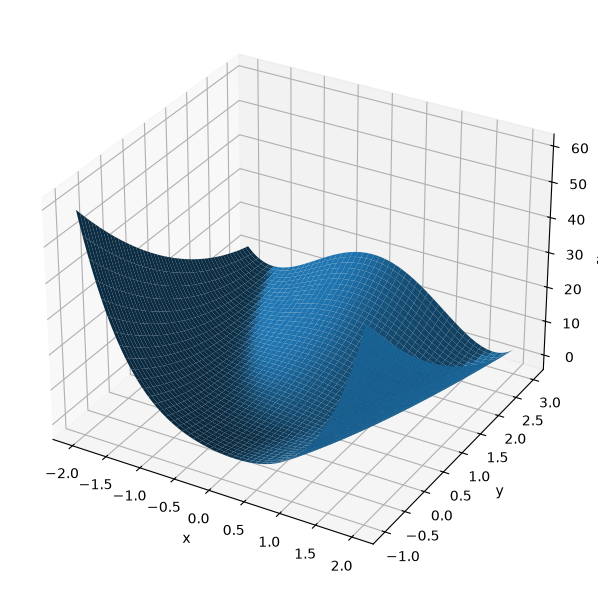

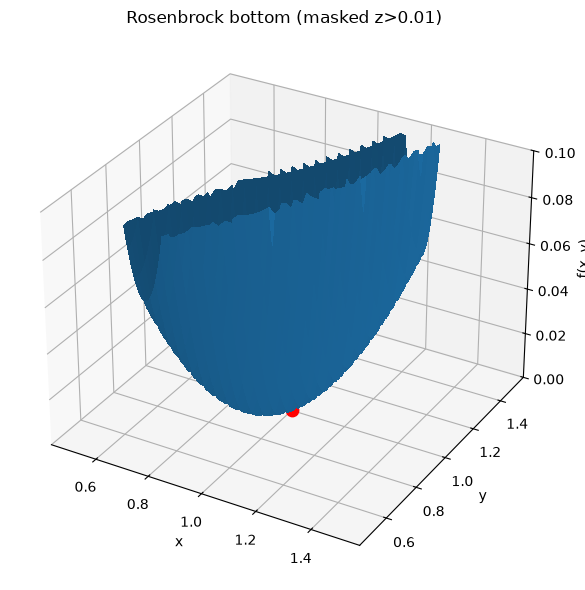

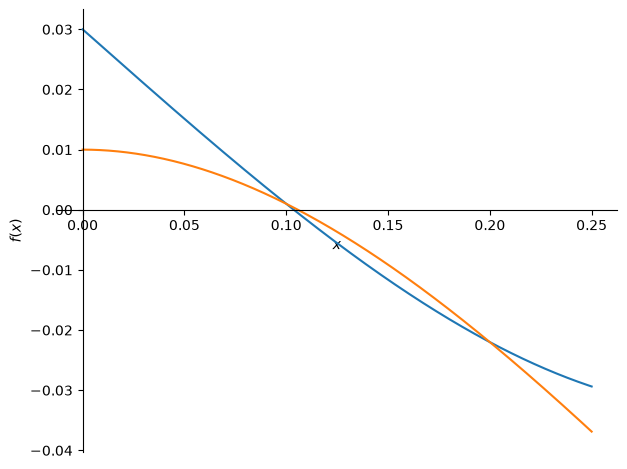

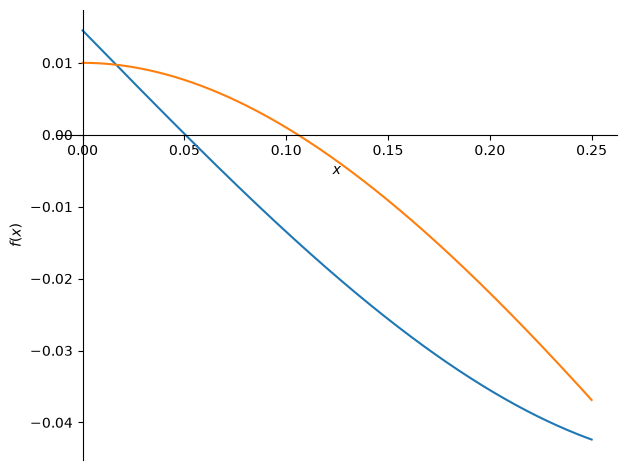

In [15]:
%matplotlib inline

# b に 0.1 を代入した式を用意する
g_sub = g.subs(b, 0.1)
h_sub = h.subs(b, 0.1)

# 代入済みの式と、b=0.1 を反映させた範囲でプロットする
pf = plot(g_sub, h_sub, (x, 0.1 - 0.1, 0.1 / 2 * 5))

In [16]:
s1=solve(g-h,x)
s1

[0.164503986781756*b, 2.73549601321824*b]

In [17]:
s1[0]

0.164503986781756*b

In [18]:
integrate(h-g,(x,s1[0],s1[1]))

2.83237621579087*b**3

In [19]:
integrate(g-h,(x,s1[1],t))

2.7961047745621*b**3 + 0.45*b**2*t - 1.45*b*t**2 + 0.333333333333333*t**3

In [20]:
S_T=integrate(h-g,(x, s1[0], t))
S_T

0.0362714412287656*b**3 - 0.45*b**2*t + 1.45*b*t**2 - 0.333333333333333*t**3

In [21]:
solve(S_T, t)

[4.02099202643649*b,
 b*(0.164503986781756 - 4.01562405549782e-9*I),
 b*(0.164503986781756 + 4.01562405549782e-9*I)]